In [3]:
import Pkg

Pkg.activate(dirname(@__DIR__))
Pkg.add(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"])
Pkg.status(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"]; mode = Pkg.PKGMODE_MANIFEST)
Pkg.instantiate()
Base.active_project()

  Activating project at `~/Documents/Git`
    Updating registry at `~/.julia/registries/General.toml`


Status 

     Project No packages added to or removed from `~/Documents/Git/Project.toml`
    Manifest No packages added to or removed from `~/Documents/Git/Manifest.toml`


`~/Documents/Git/Manifest.toml`
  [47edcb42] ADTypes v1.24.0
  [f3fd9213] Attractors v2.0.5
  [6e4b80f9] BenchmarkTools v1.8.0
  [159f3aea] Cairo v1.1.1
⌃ [13f3f980] CairoMakie v0.15.15
  [608a59af] ChaosTools v3.5.4
⌃ [5ae59095] Colors v0.13.2
  [38540f10] CommonSolve v0.2.14
  [34da2185] Compat v4.18.1
⌃ [ab4b797d] ComplexityMeasures v3.11.0
  [864edb3b] DataStructures v0.19.6
  [5732040d] DelayEmbeddings v2.9.0
⌃ [2b5f629d] DiffEqBase v7.21.3
⌅ [ffbed154] DocStringExtensions v0.9.5
  [61744808] DynamicalSystems v3.7.0
  [6e36e845] DynamicalSystemsBase v3.19.3
  [5789e2e9] FileIO v1.20.0
  [4665ce21] FractalDimensions v1.9.6
  [b38be410] FreeType v4.1.1
  [5c1252a2] GeometryBasics v0.5.13
⌃ [682c06a0] JSON v1.10.0
⌅ [ee78f7c6] Makie v0.24.15
  [1dea7af3] OrdinaryDiffEq v7.8.1
⌃ [6ad6398a] OrdinaryDiffEqBDF v2.4.12
⌃ [bbf590c4] OrdinaryDiffEqCore v4.18.1
  [50262376] OrdinaryDiffEqDefault v2.6.2
  [43230ef6] OrdinaryDiffEqRosenbrock v2.7.5
  [b1df2697] OrdinaryDiffEqTsit5 v2.1.5
  [79

"/home/stan/Documents/Git/Project.toml"

In [4]:
using DynamicalSystems
using CairoMakie
using Statistics

## Question 1

### 1.3

In [5]:
function q1(u, p, t)
    x, y, z = u
    a, b, c = p
    dx = - y - z
    dy = x + a*y
    dz = b + z*(x-c)
    return SVector(dx, dy, dz)
end

q1 (generic function with 1 method)

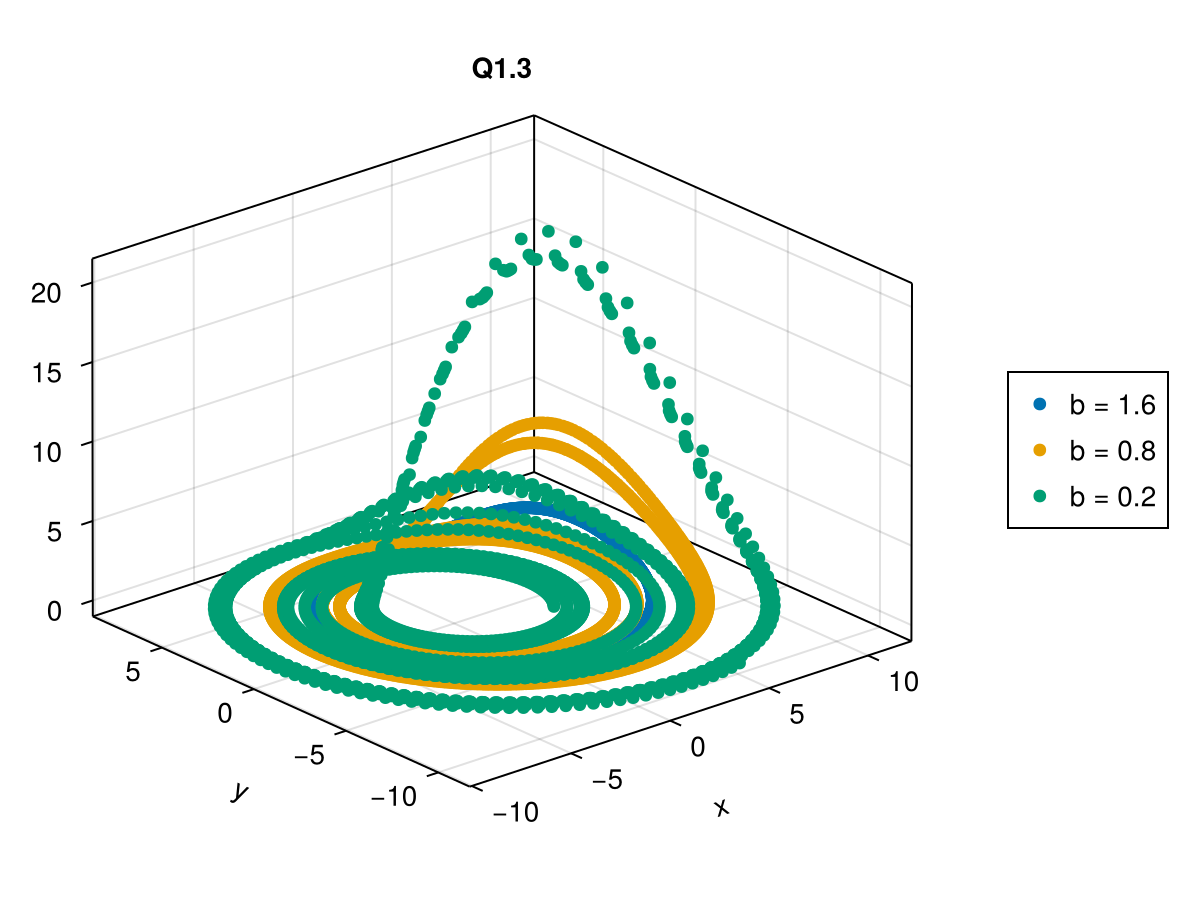

CairoMakie.Screen{IMAGE}


In [7]:
b_vals = [1.6, 0.8, 0.2]
colours = ["red", "green", "blue"]
graphs = []

fig = Figure()
ax = Axis3(fig[1, 1]; title = "Q1.3")

for b in b_vals
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1vals = CoupledODEs(q1, u0, p0)
    total_time = 100
    X, t = trajectory(q1vals, total_time; Ttr = 1000, Δt = 0.05)
    graph = scatter!(ax, X)
    push!(graphs, graph)
end

Legend(fig[1, 2], graphs, ["b = 1.6", "b = 0.8", "b = 0.2"])
display(fig)

### 1.4

In [8]:
mean_x_vals = []
mean_z_vals = []
b_values = []
for b in 0.2:0.01:1.6
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1_4vals = CoupledODEs(q1, u0, p0)
    total_time = 1_000
    X, t = trajectory(q1_4vals, total_time; Ttr = 0000)
    x_vals, _, z_vals = columns(X)
    mean_x = mean(x_vals)
    mean_z = mean(z_vals)
    push!(mean_x_vals, mean_x)
    push!(mean_z_vals, mean_z)
    push!(b_values, b)
end



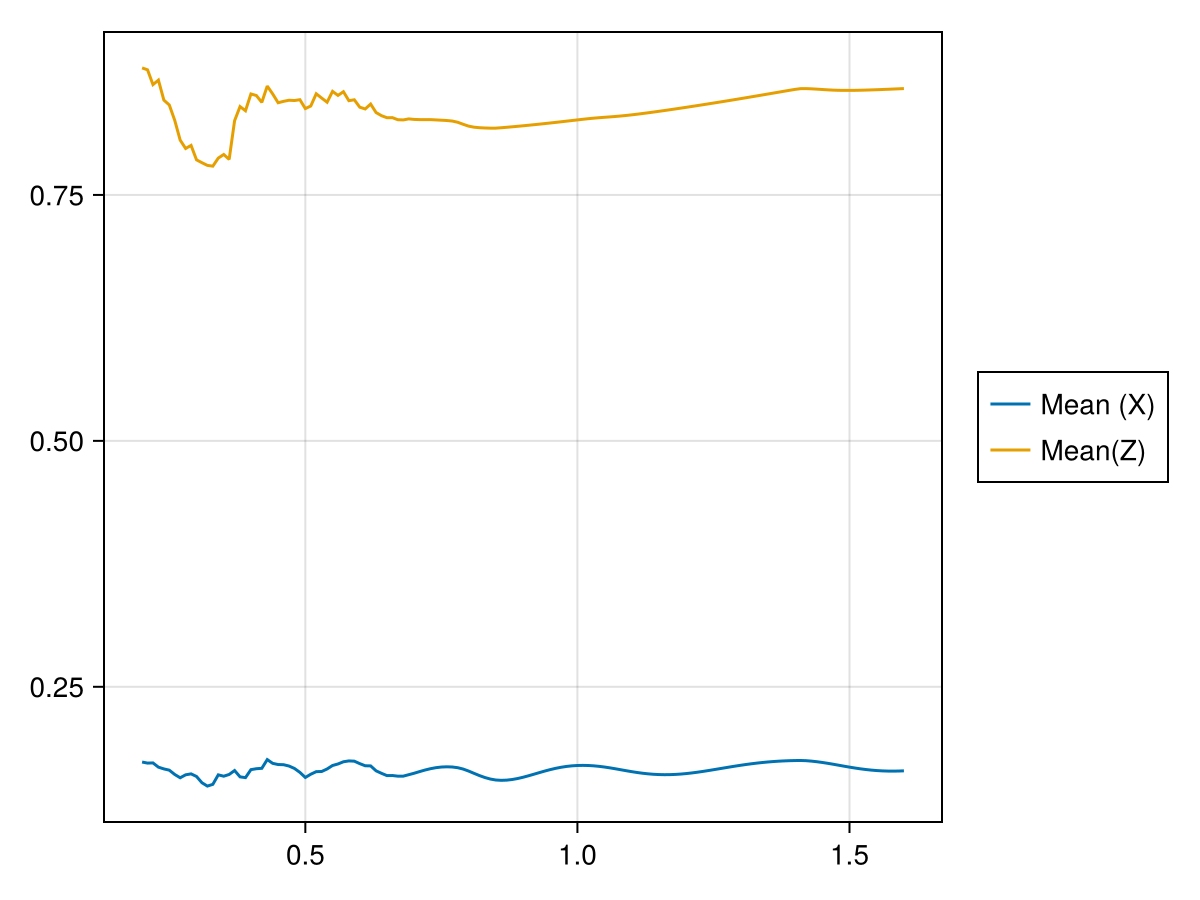

In [9]:
fig = Figure()
ax = Axis(fig[1,1])
x_graph = lines!(ax, b_values, mean_x_vals)
z_graph = lines!(ax, b_values, mean_z_vals)
Legend(fig[1, 2], [x_graph, z_graph], ["Mean (X)", "Mean(Z)"])
fig

In [10]:
display("text/markdown", Base.doc(poincaresos))

```julia
poincaresos(A::AbstractStateSpaceSet, plane; kwargs...) → P::StateSpaceSet
```

Calculate the Poincaré surface of section of the given dataset with the given `plane` by performing linear interpolation betweeen points that sandwich the hyperplane.

Argument `plane` and keywords `direction, warning, save_idxs` are the same as in [`PoincareMap`](@ref).

```julia
poincaresos(ds::CoupledODEs, plane, T = 1000.0; kwargs...) → P::StateSpaceSet
```

Return the iterations of `ds` on the Poincaré surface of section with the `plane`, by evolving `ds` up to a total of `T`. Return a [`StateSpaceSet`](@ref) of the points that are on the surface of section.

This function initializes a [`PoincareMap`](@ref) and steps it until its [`current_crossing_time`](@ref) exceeds `T`. You can also use [`trajectory`](@ref) with [`PoincareMap`](@ref) to get a sequence of `N::Int` points instead.

The keywords `Ttr, save_idxs` act as in [`trajectory`](@ref). See [`PoincareMap`](@ref) for `plane` and all other keywords.


In [25]:
display("text/markdown", Base.doc(PoincareMap))

```julia
PoincareMap <: DiscreteTimeDynamicalSystem
PoincareMap(ds::CoupledODEs, plane; kwargs...) → pmap
```

A discrete time dynamical system that produces iterations over the Poincaré map[^DatserisParlitz2022] of the given continuous time `ds`. This map is defined as the sequence of points on the Poincaré surface of section, which is defined by the `plane` argument.

Iterating `pmap` also mutates `ds` which is referenced in `pmap`.

See also [`StroboscopicMap`](@ref), [`poincaresos`](@ref).

## Keyword arguments

  * `direction = -1`: Only crossings with `sign(direction)` are considered to belong to the surface of section. Negative direction means going from less than $b$ to greater than $b$.
  * `u0 = nothing`: Specify an initial state. If `nothing` it is the `current_state(ds)`.
  * `rootkw = (xrtol = 1e-6, atol = 1e-8)`: A `NamedTuple` of keyword arguments passed to `find_zero` from [Roots.jl](https://github.com/JuliaMath/Roots.jl).
  * `Tmax = 1e3`: The argument `Tmax` exists so that the integrator can terminate instead of being evolved for infinite time, to avoid cases where iteration would continue forever for ill-defined hyperplanes or for convergence to fixed points, where the trajectory would never cross again the hyperplane. If during one `step!` the system has been evolved for more than `Tmax`, then `step!(pmap)` will terminate and error.

## Description

The Poincaré surface of section is defined as sequential transversal crossings a trajectory has with any arbitrary manifold, but here the manifold must be a hyperplane. `PoincareMap` iterates over the crossings of the section.

If the state of `ds` is $\mathbf{u} = (u_1, \ldots, u_D)$ then the equation defining a hyperplane is

$$
a_1u_1 + \dots + a_Du_D = \mathbf{a}\cdot\mathbf{u}=b
$$

where $\mathbf{a}, b$ are the parameters of the hyperplane.

In code, `plane` can be either:

  * A `Tuple{Int, <: Real}`, like `(j, r)`: the plane is defined as when the `j`th variable of the system equals the value `r`.
  * A vector of length `D+1`. The first `D` elements of the vector correspond to $\mathbf{a}$ while the last element is $b$.

`PoincareMap` uses `ds`, higher order interpolation from DifferentialEquations.jl, and root finding from Roots.jl, to create a high accuracy estimate of the section.

`PoincareMap` follows the [`DynamicalSystem`](@ref) interface with the following adjustments:

1. `dimension(pmap) == dimension(ds)`, even though the Poincaré map is effectively 1 dimension less.
2. Like [`StroboscopicMap`](@ref) time is discrete and counts the iterations on the surface of section. [`initial_time`](@ref) is always `0` and [`current_time`](@ref) is current iteration number.
3. A new function [`current_crossing_time`](@ref) returns the real time corresponding to the latest crossing of the hyperplane. The corresponding state on the hyperplane is `current_state(pmap)` as expected.
4. For the special case of `plane` being a `Tuple{Int, <:Real}`, a special `reinit!` method is allowed with input state of length `D-1` instead of `D`, i.e., a reduced state already on the hyperplane that is then converted into the `D` dimensional state.
5. The `initial_state(pmap)` returns the state initial state of the map. This is not `u0` because `u0` is evolved forwards until it resides on the Poincaré plane.
6. In the `reinit!` function, the `t0` keyword denotes the starting time of the continuous time dynamical system, as the starting time of the `PoincareMap` is by definition always 0.

## Example

```julia
using DynamicalSystemsBase, PredefinedDynamicalSystems
ds = Systems.rikitake(zeros(3); μ = 0.47, α = 1.0)
pmap = poincaremap(ds, (3, 0.0))
step!(pmap)
next_state_on_psos = current_state(pmap)
```

[^DatserisParlitz2022]: Datseris & Parlitz 2022, *Nonlinear Dynamics: A Concise Introduction Interlaced with Code*, [Springer Nature, Undergrad. Lect. Notes In Physics](https://doi.org/10.1007/978-3-030-91032-7)


In [12]:
display("text/markdown", Base.doc(current_crossing_time))

```julia
current_crossing_time(pmap::PoincareMap) → tcross
```

Return the time of the latest crossing of the Poincare section.


In [13]:
set_parameter!(q1_4vals, 2, 0.2) # Set 2nd param (b) to 0.2
current_parameters(q1_4vals)
u0 = [5.2, 0, 0]

UndefVarError: UndefVarError: `q1_4vals` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [14]:
function psos1(A, index, value)
    # Estimate poincare section of traj(A) with hyperplane defined for when var(traj) with given index
    # crosses a specific value (- => +)
    # Use interpolation
    plane = (index, value)
    pmap = poincaresos(A, plane, 1000, direction = -1)
    return pmap
end

psos1 (generic function with 1 method)

┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/R

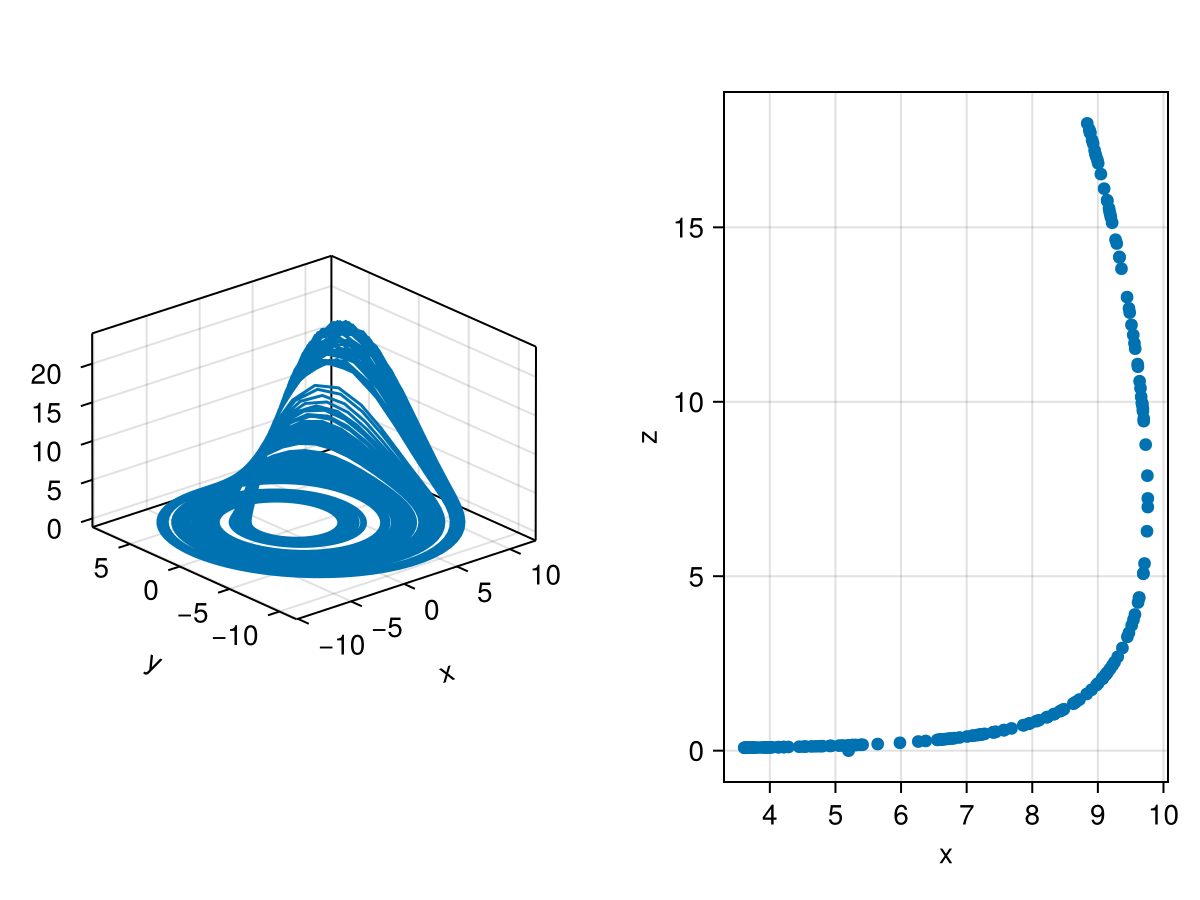

In [15]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
poincare_map = psos1(A, 2, 0.0)
fig = Figure()
ax = Axis3(fig[1, 1])
X, t = trajectory(A, 1000)
lines!(ax, X)
ax = Axis(fig[1, 2], xlabel = "x", ylabel="z")
scatter!(ax, poincare_map[:, 1], poincare_map[:, 3])
fig

In [26]:
"""
Function to calculate the crossing times of a trajectory over a hyperplane using the poincare poincare_map

Args:
    A: ODE
    tvec: Vector of times (used as end-point of measurings)
    index: Index of variable to use, ie x = 1, y = 2
    value: Value of fixed variable on hyperplane

Returns:
    Vector(float): Crossing times up to (strictly less than) maximum(tvec)
"""
function psos2(A, tvec, index, value)
    max_time = maximum(tvec)
    times = []
    plane = (index, value)
    pmap = poincaremap(A, plane, max_time, direction = -1)
    while true
        step!(pmap)
        t_cross = current_crossing_time(pmap)
        if t_cross < max_time
            push!(times, t_cross)
        else
            return times
        end
    end
end

psos2 (generic function with 1 method)

┌ Warning: `poincaremap` is deprecated in favor of `PoincareMap`.
└ @ DynamicalSystemsBase /home/stan/.julia/packages/DynamicalSystemsBase/0lljD/src/deprecations.jl:81
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_shi.jl:97
┌ Warning: This bracketing method only has tolerances `xatol` and `xrtol`. Any settings for `atol` or `rtol` are ignored.
└ @ Roots /home/stan/.julia/packages/Roots/y0UMG/src/Bracketing/alefeld_potra_sh

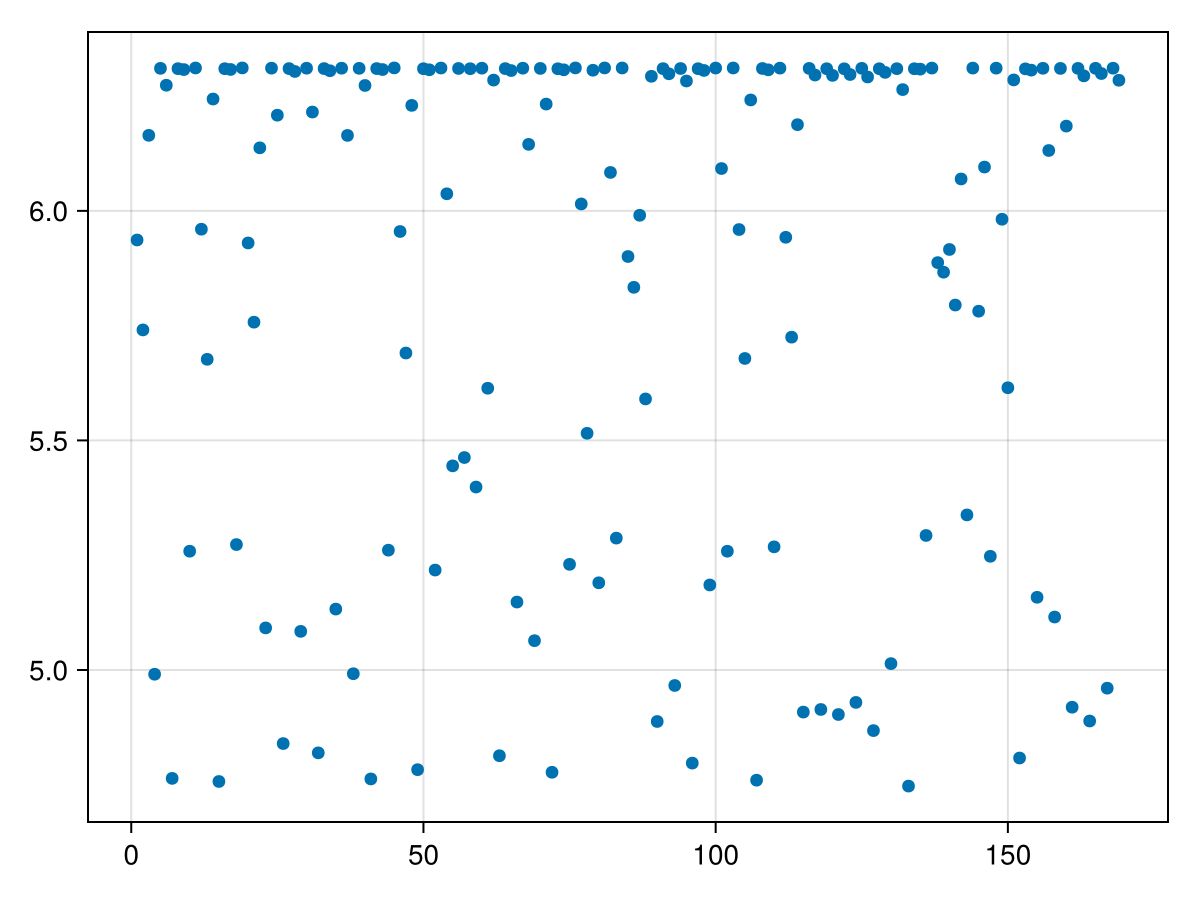

In [28]:
A = CoupledODEs(q1, [5.2, 0, 0], [0.2, 0.2, 5.7])
absolute_times = (psos2(A, t, 2, 0.0))
# step!(p_map)
# current_crossing_time(p_map)
return_times = diff(absolute_times)
scatter(return_times)

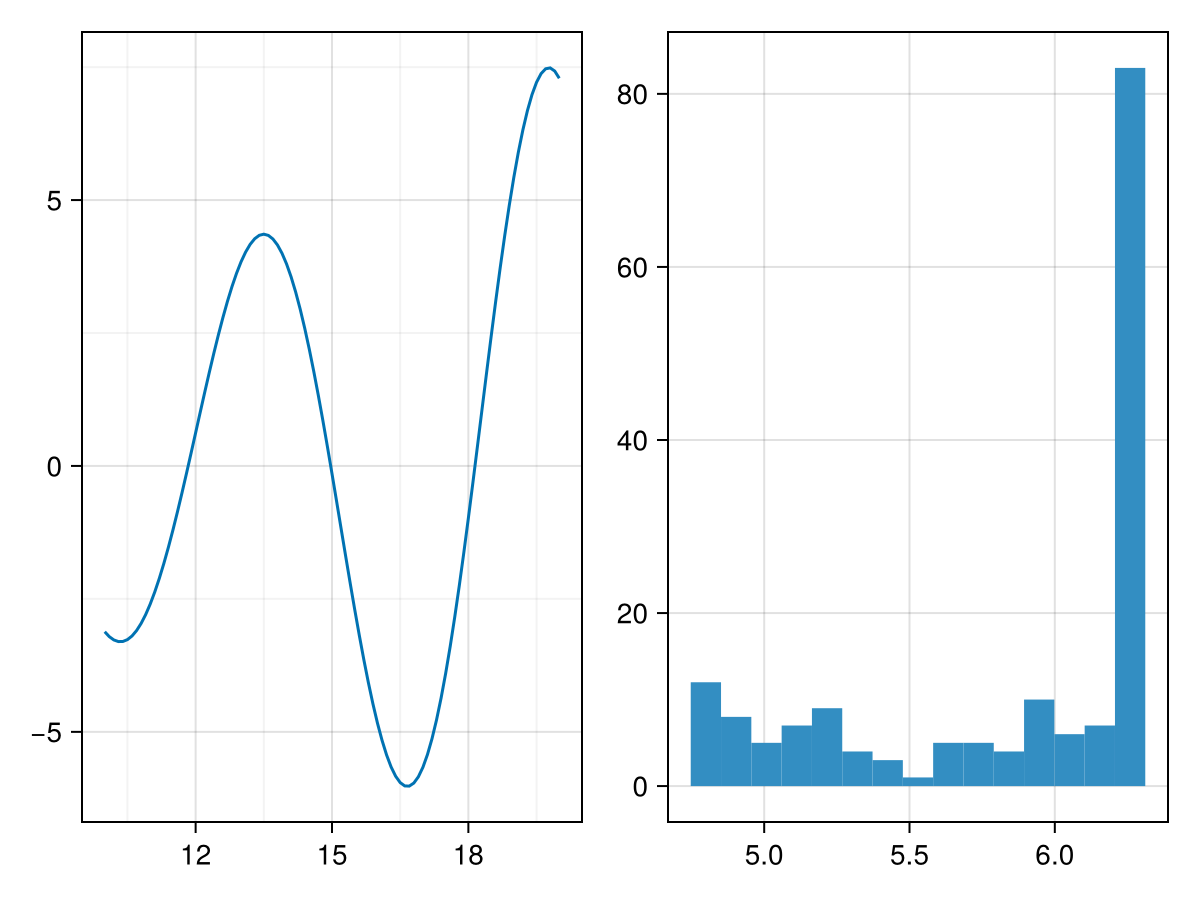

In [42]:
X, t = trajectory(A, 10 ;Ttr = 10) # Evaluate the ODE for t in [10, 20]
y_vals = X[:, 2]
fig = Figure()
ax = Axis(fig[1, 1], xminorgridvisible = true, yminorgridvisible=true)
lines!(ax, t, y_vals)
ax = Axis(fig[1, 2])
sorted_return_times = sort(return_times)
median_return_time = sorted_return_times[div(length(sorted_return_times), 2)]
hist!(ax, return_times)
fig

## The period here is roughly 6 seconds, as reflected in the roughly 6 second return time

In [ ]:
function NP_DS(u, p, t)
    N, P = u
    r, δ = p
    c, μ, ν, α, β, χ = 0.19, 0.03, 0.003, 800, 1.5, 0.004

    s = α*N*P/(β + N)

    dN = r*N* (1 - (c/r)*N) * ((N - μ)/(N + ν)) - s
    dP = χ*s - δ*P

    return SVector(dN, dP)
end

NP_DS (generic function with 1 method)

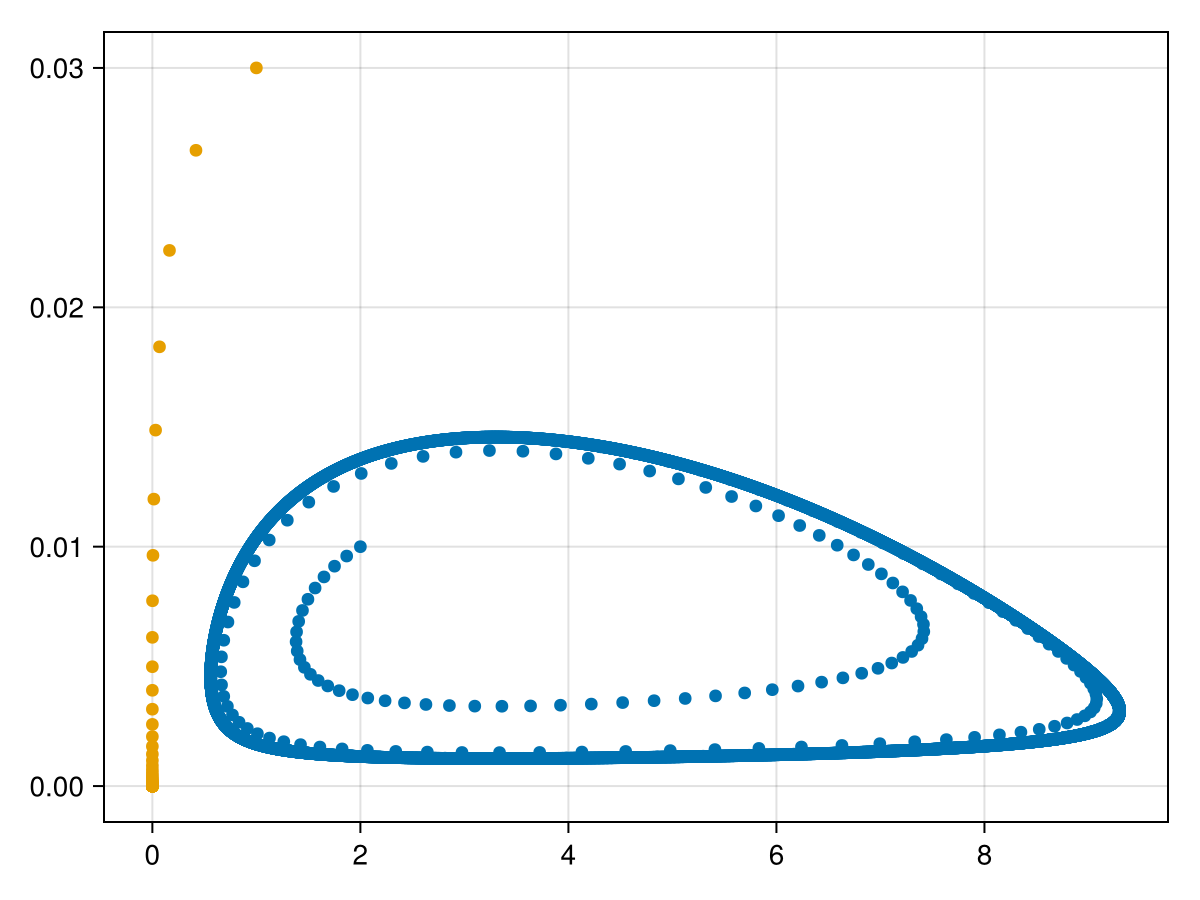

In [99]:
fig = Figure()
ax = Axis(fig[1, 1])
points = [[2, 0.01], [1, 3e-2]]
p0 = [2, 2.2]
for u0 in points
    NP_system = CoupledODEs(NP_DS, u0, p0)
    total_time = 1000
    X, t = trajectory(NP_system, total_time)
    scatter!(ax, X)
end
fig

In [93]:
X


2-dimensional StateSpaceSet{Float64} with 10001 points
 10.0      0.01
  9.43584  0.0105885
  8.92155  0.0111875
  8.44093  0.0117945
  7.98205  0.0124061
  7.53589  0.013018
  7.09551  0.0136245
  6.65555  0.0142186
  6.21188  0.0147913
  5.76145  0.0153315
  ⋮        
  7.77427  0.00843845
  7.60801  0.00885141
  7.43115  0.00927538
  7.24318  0.00970898
  7.04359  0.0101505
  6.83188  0.0105977
  6.60755  0.011048
  6.37014  0.0114979
  6.11925  0.0119435

In [83]:
list = [1, 2, 3]
list[2:length(list)]

2-element Vector{Int64}:
 2
 3

In [ ]:
function simple_grouping(features, r)
    groups = [features[1]]
    group_indeces = [1]
    for point in features[2:length(features)]
        for i in lenght(groups)
            if norm(point, groups[i]) < r
                push!(group_indeces, i)
            else 
                push!(groups, point)
                push!(group_indeces, i+1)
    pass
end